# 04 — Stochastic Moving Enemies (DQN)

This experiment extends **03 — Moving Goal**. The moving Goal is retained, while the five deterministic patrols are replaced with independent random-walk enemies.

**What changes in 04**
- Enemies move in random legal cardinal directions; they do not follow fixed loops.
- Each enemy has a distinct movement interval (1–5 environment steps). The speed assignment is shuffled at every reset.
- At a movement opportunity, an enemy can pause for a random duration. The pause probability and duration are configurable.
- Enemies never overlap each other, the Agent, walls, or the current Goal.
- The local sensor and 24-dimensional observation remain unchanged. The two old patrol-phase inputs are zero because there is no shared deterministic patrol phase.

The moving Goal and potential-based reward shaping from version 03 are preserved. Training starts from a fresh DQN; no old checkpoint is silently reused.

In [11]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Find the project root whether Jupyter was started here or in notebooks/.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "src" / "navigation_rl").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root containing src/navigation_rl"
    )
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import torch

from navigation_rl.environment import ACTION_NAMES, OBSERVATION_DIM
from navigation_rl.dqn import (
    DQNAgent,
    DQNConfig,
    TrainingConfig,
    plot_training_history,
    train_agent,
)
from stochastic_enemy_dqn.environment import (
    DEFAULT_ENEMY_PAUSE_DURATION,
    DEFAULT_ENEMY_PAUSE_PROBABILITY,
    DEFAULT_ENEMY_SPEED_INTERVALS,
    StochasticEnemyNavigationGridWorld,
)
from stochastic_enemy_dqn.evaluation import evaluate_stochastic_enemy_policy
from stochastic_enemy_dqn.episode_video import render_stochastic_enemy_episode_videos

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
print("Observation dimension:", OBSERVATION_DIM)

Device: cpu
Observation dimension: 24


## 1. Inspect the stochastic environment before training

First inspect the actual dynamics. The enemy's speed is its **movement interval**: an interval of 1 gives it a movement opportunity every step, while an interval of 5 gives it one every five steps. A square marker indicates a currently paused enemy.

,Enemy,Speed interval (steps),Initial position,Initial pause remaining
0,E1,2,"(13, 0)",0
1,E2,3,"(9, 13)",0
2,E3,4,"(7, 13)",0
3,E4,5,"(0, 13)",0
4,E5,1,"(3, 17)",0


Agent: (0, 0)
Moving Goal: (17, 4)
Observation shape: (24,)


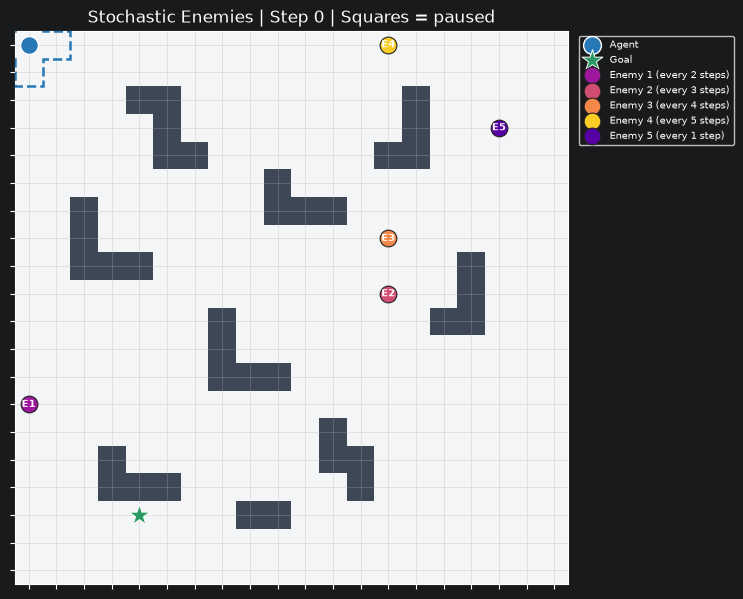

In [2]:
GOAL_MOVE_INTERVAL = 3
MAX_STEPS = 500
ENEMY_SPEED_INTERVALS = DEFAULT_ENEMY_SPEED_INTERVALS
PAUSE_PROBABILITY = DEFAULT_ENEMY_PAUSE_PROBABILITY
PAUSE_DURATION = DEFAULT_ENEMY_PAUSE_DURATION

inspection_env = StochasticEnemyNavigationGridWorld(
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
)
observation, reset_info = inspection_env.reset(seed=2026)

speed_table = pd.DataFrame({
    "Enemy": [f"E{i + 1}" for i in range(inspection_env.enemy_count)],
    "Speed interval (steps)": reset_info["enemy_speed_intervals"],
    "Initial position": reset_info["enemy_positions"],
    "Initial pause remaining": reset_info["enemy_pause_remaining"],
})
display(speed_table)
print("Agent:", inspection_env.agent_pos)
print("Moving Goal:", inspection_env.goal_pos)
print("Observation shape:", observation.shape)
inspection_env.render(show_sensor=True)
plt.show()

,step,enemy,position,interval,moved,paused,pause_remaining
0,1,E1,"(13, 0)",2,False,False,0
1,1,E2,"(9, 14)",3,True,False,0
2,1,E3,"(7, 13)",4,False,False,0
3,1,E4,"(0, 13)",5,False,False,0
4,1,E5,"(3, 16)",1,True,False,0
5,2,E1,"(14, 0)",2,True,False,0
6,2,E2,"(9, 14)",3,False,False,0
7,2,E3,"(7, 13)",4,False,False,0
8,2,E4,"(0, 13)",5,False,False,0
9,2,E5,"(3, 17)",1,True,False,0


Actual enemy moves: 47
Actual pause steps: 12


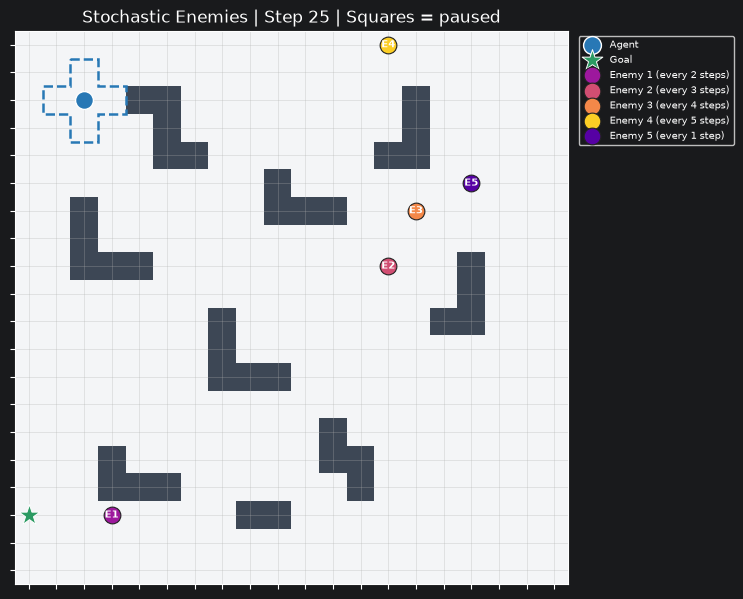

In [3]:
# Observe several real environment updates and record each enemy's movement/pause state.
demo_rows = []
demo_rng = np.random.default_rng(2026)
for _ in range(25):
    action = int(demo_rng.integers(4))
    observation, reward, terminated, truncated, info = inspection_env.step(action)
    for enemy_id, position in enumerate(info["enemy_positions"]):
        demo_rows.append({
            "step": info["steps"],
            "enemy": f"E{enemy_id + 1}",
            "position": position,
            "interval": info["enemy_speed_intervals"][enemy_id],
            "moved": info["enemy_moved_this_step"][enemy_id],
            "paused": info["enemy_paused_this_step"][enemy_id],
            "pause_remaining": info["enemy_pause_remaining"][enemy_id],
        })
    if terminated or truncated:
        break

demo_history = pd.DataFrame(demo_rows)
display(demo_history.head(15))
print("Actual enemy moves:", int(demo_history["moved"].sum()))
print("Actual pause steps:", int(demo_history["paused"].sum()))
inspection_env.render(show_sensor=True)
plt.show()

## 2. Experiment configuration

The DQN architecture and main hyperparameters stay aligned with the earlier experiments. The episode limit is increased to 500 because the task is harder: the Goal moves and the enemies move stochastically. The training cell below is deliberately separate; opening the notebook does not launch a long training run.

In [12]:
SEED = 42
NUM_EPISODES = 1_000
NUM_EVAL_EPISODES = 200
MAX_STEPS = 500
VIDEO_EPISODES = [
    episode for episode in (1, 10, 50, 100, 200, 500, 1_000)
    if episode <= NUM_EPISODES
]

GOAL_MOVE_INTERVAL = 3
ENEMY_SPEED_INTERVALS = (1, 2, 3, 4, 5)
PAUSE_PROBABILITY = 0.20
PAUSE_DURATION = (1, 4)
SPAWN_MIN_DISTANCE = 4
OUTPUT_DIR = PROJECT_ROOT / "results_stochastic_enemies"

DQN_CONFIG = DQNConfig(device=DEVICE)
TRAIN_CONFIG = TrainingConfig(
    episodes=NUM_EPISODES,
    seed=SEED,
    evaluation_episodes=NUM_EVAL_EPISODES,
    evaluation_seed=50_000,
    max_steps=MAX_STEPS,
    log_interval=20,
    checkpoint_interval=0,
    output_dir=str(OUTPUT_DIR),
    show_progress=True,
)

env = StochasticEnemyNavigationGridWorld(
    gamma=DQN_CONFIG.gamma,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
    spawn_min_distance=SPAWN_MIN_DISTANCE,
)

print("DQN observation dimension:", DQN_CONFIG.observation_dim)
print("DQN actions:", DQN_CONFIG.num_actions)
print("Goal moves every:", GOAL_MOVE_INTERVAL, "steps")
print("Enemy speed intervals:", ENEMY_SPEED_INTERVALS)
print("Pause probability:", PAUSE_PROBABILITY)
print("Pause duration:", PAUSE_DURATION)
print("Training episodes:", NUM_EPISODES)
print("Max steps per episode:", MAX_STEPS)
# print("Output directory:", OUTPUT_DIR)

DQN observation dimension: 24
DQN actions: 4
Goal moves every: 3 steps
Enemy speed intervals: (1, 2, 3, 4, 5)
Pause probability: 0.2
Pause duration: (1, 4)
Training episodes: 1000
Max steps per episode: 500


## 3. Smoke test

Run a short interaction/update test before committing to the full experiment. It verifies that observations, replay insertion, and gradient updates work with the new environment.

In [5]:
smoke_config = DQNConfig(
    learning_rate=DQN_CONFIG.learning_rate,
    gamma=DQN_CONFIG.gamma,
    replay_capacity=256,
    batch_size=16,
    learning_starts=16,
    train_frequency=1,
    target_update_interval=10,
    epsilon_decay_steps=100,
    hidden_dim=DQN_CONFIG.hidden_dim,
    device=DEVICE,
)
smoke_agent = DQNAgent(smoke_config, seed=SEED)
smoke_env = StochasticEnemyNavigationGridWorld(
    gamma=smoke_config.gamma,
    max_steps=60,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
)
obs, _ = smoke_env.reset(seed=SEED)
smoke_losses = []
for step in range(60):
    action = smoke_agent.choose_action(obs, explore=True)
    next_obs, reward, terminated, truncated, info = smoke_env.step(action)
    loss = smoke_agent.store_transition(obs, action, reward, next_obs, terminated)
    if loss is not None:
        smoke_losses.append(loss)
    obs = next_obs
    if terminated or truncated:
        obs, _ = smoke_env.reset(seed=SEED + step + 1)

assert obs.shape == (OBSERVATION_DIM,)
assert len(smoke_agent.replay_buffer) >= 16
assert len(smoke_losses) > 0
print("Smoke test passed.")
print("Replay transitions:", len(smoke_agent.replay_buffer))
print("Gradient updates:", len(smoke_losses))
print("Final smoke-test loss:", f"{smoke_losses[-1]:.5f}")

Smoke test passed.
Replay transitions: 60
Gradient updates: 45
Final smoke-test loss: 0.12428


## 4. Train a new DQN

The selected episode numbers are recorded from the **actual epsilon-greedy training interaction**. Later video rendering replays those saved states; it does not generate replacement trajectories.

In [6]:
agent = DQNAgent(DQN_CONFIG, seed=SEED)
history = train_agent(
    agent,
    env,
    TRAIN_CONFIG,
    record_episodes=VIDEO_EPISODES,
)

print("Training finished.")
print("Episodes:", len(history))
display(history.tail())

DQN training:   0%|          | 0/1000 [00:00<?, ?episode/s]

Training finished.
Episodes: 1000


,episode,episode_return,episode_length,success,blocked_actions,blocked_action_rate,epsilon,mean_loss,environment_steps,gradient_steps
995,996,22.370,53,True,2,0.037736,0.620193,0.151942,119939,29235
996,997,27.275,99,True,1,0.010101,0.619880,0.143421,120038,29260
997,998,20.885,11,True,3,0.272727,0.619845,0.117349,120049,29263
998,999,33.855,82,True,8,0.097561,0.619585,0.140084,120131,29283
999,1000,25.605,65,True,4,0.061538,0.619379,0.153696,120196,29300


## 5. Learning curves

Success rate is the primary learning diagnostic. Return alone is not sufficient because it also contains step costs and potential-based shaping.

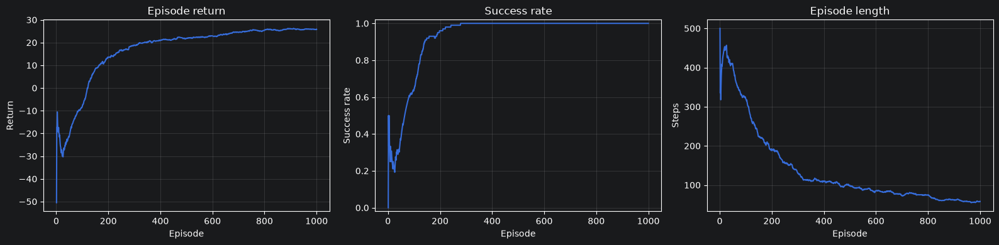

In [7]:
fig = plot_training_history(history, window=100)
plt.show()
fig.savefig(
    OUTPUT_DIR / "training_curves_stochastic_enemies.png",
    dpi=160,
    bbox_inches="tight",
)

## 6. Replay selected training episodes

Enemy colors represent their speed intervals. A square marker means the enemy is paused. The GIFs are rendered from the recorded training frames, including the enemies' actual positions and pause states.

Episode 1: success=False, steps=500


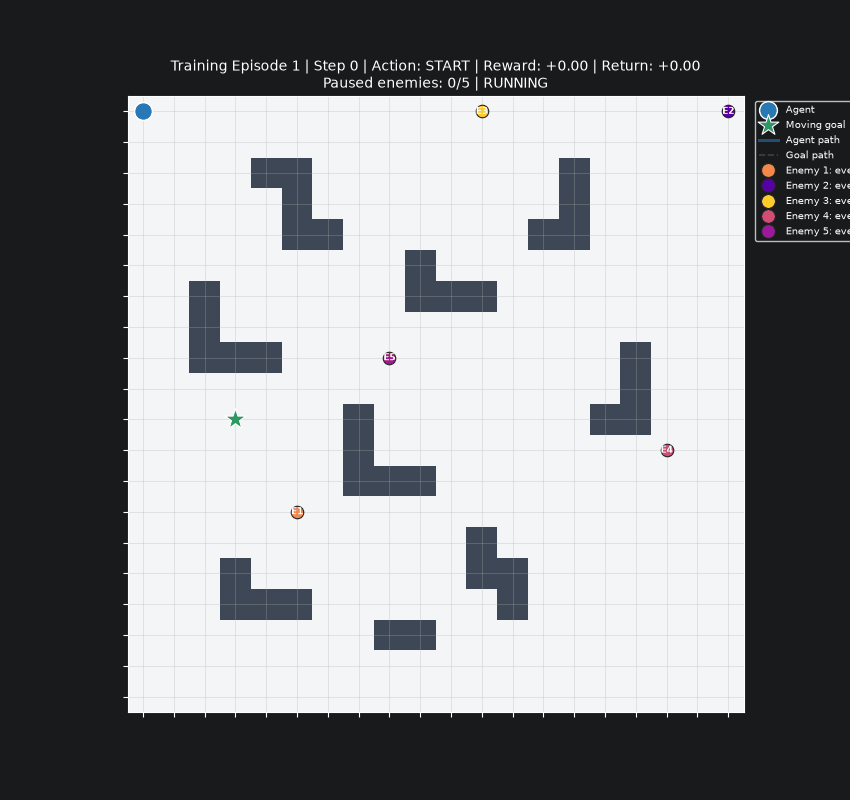

Episode 10: success=False, steps=500


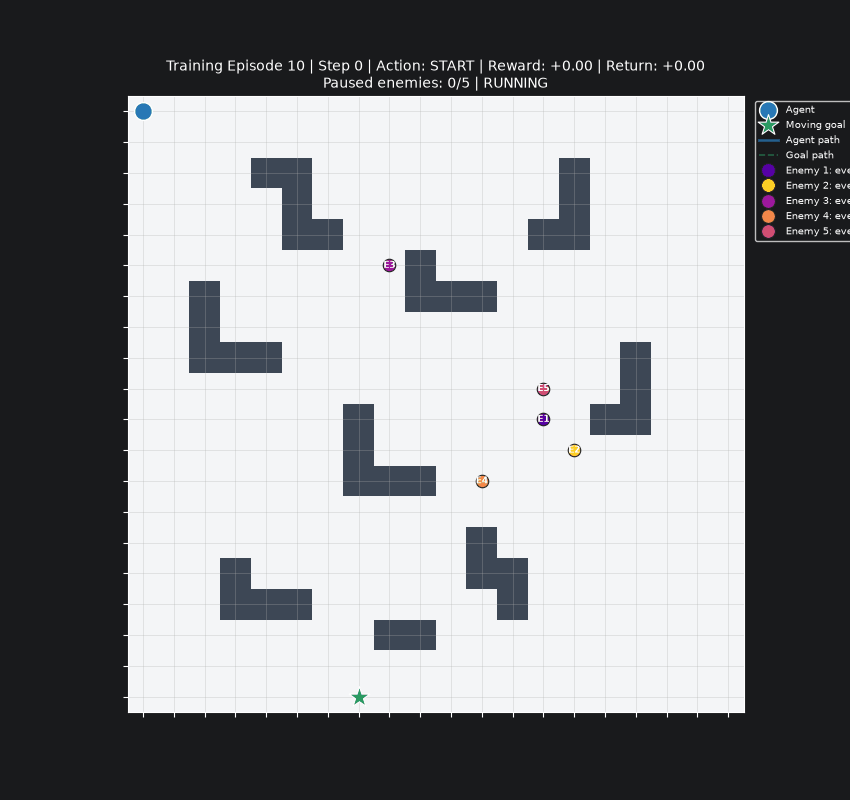

Episode 50: success=True, steps=224


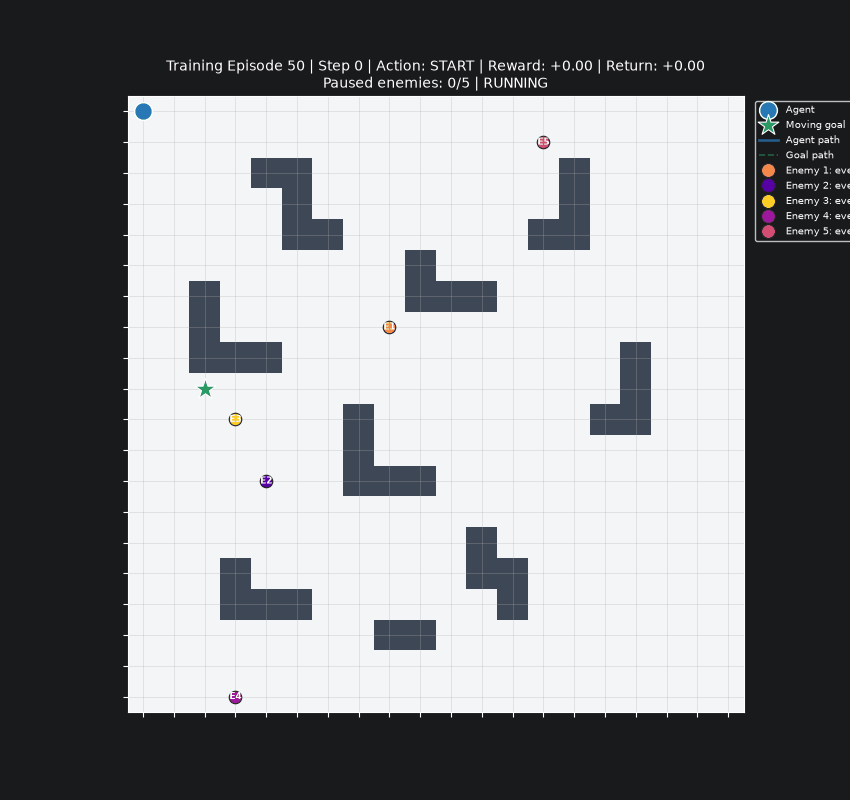

Episode 100: success=True, steps=29


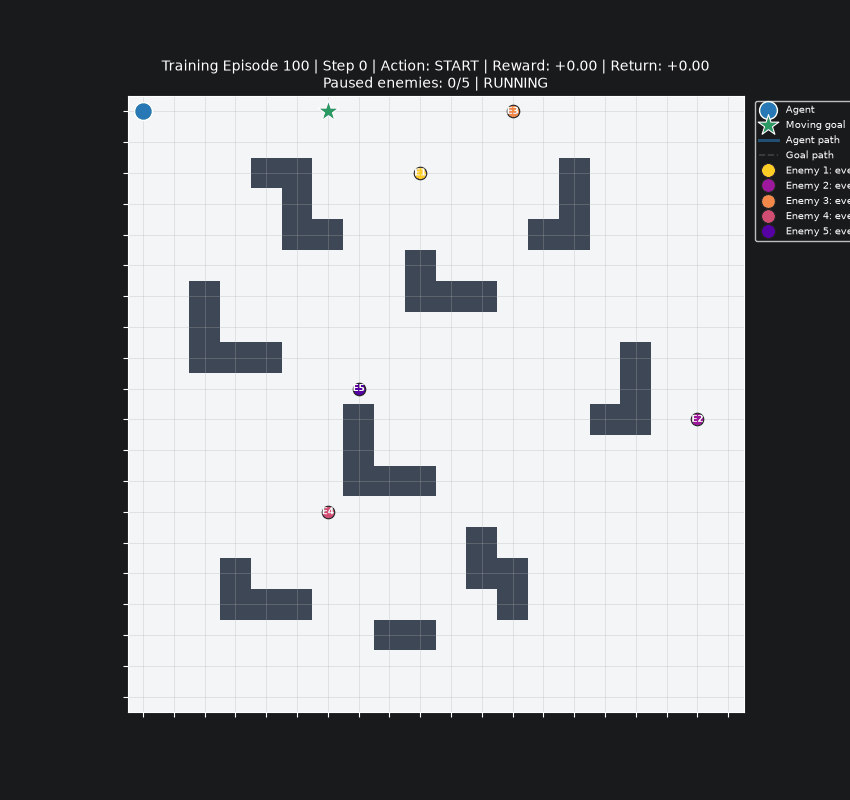

Episode 200: success=True, steps=255


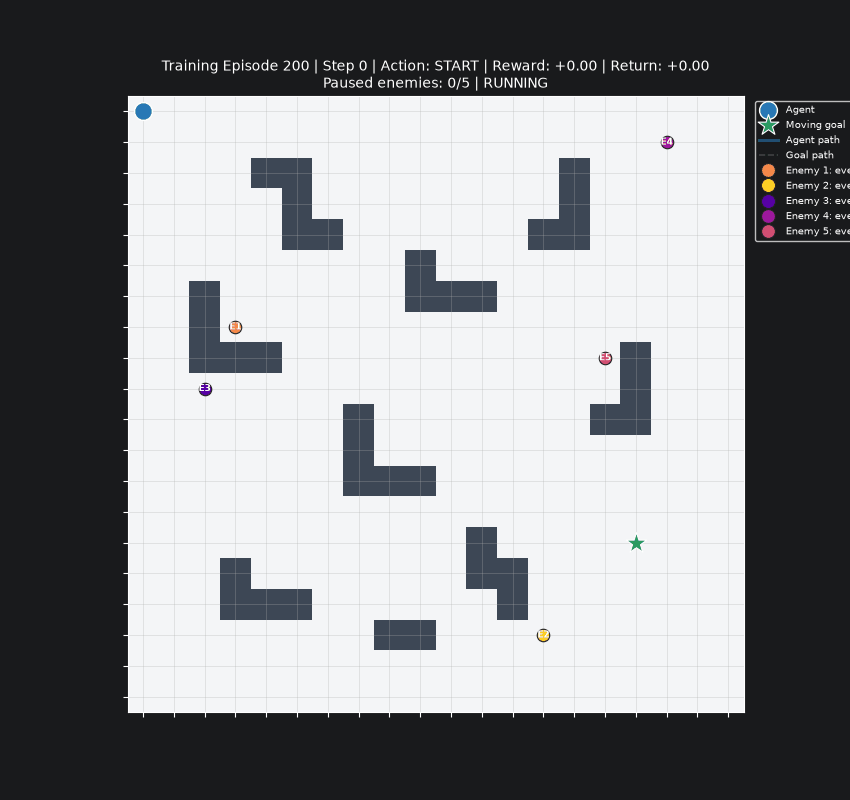

Episode 500: success=True, steps=104


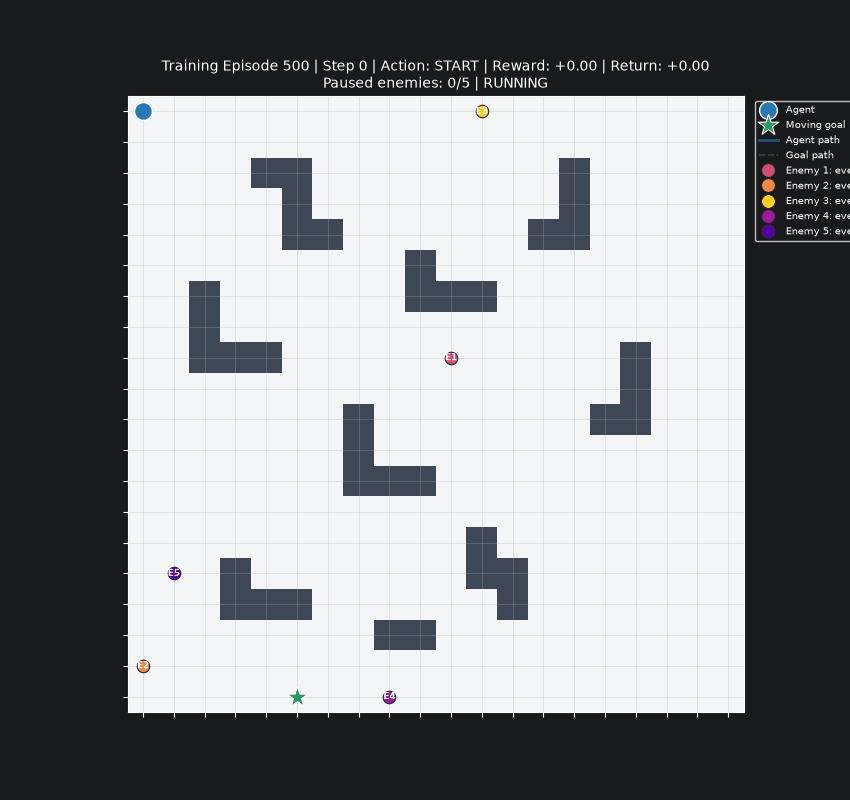

Episode 1000: success=True, steps=65


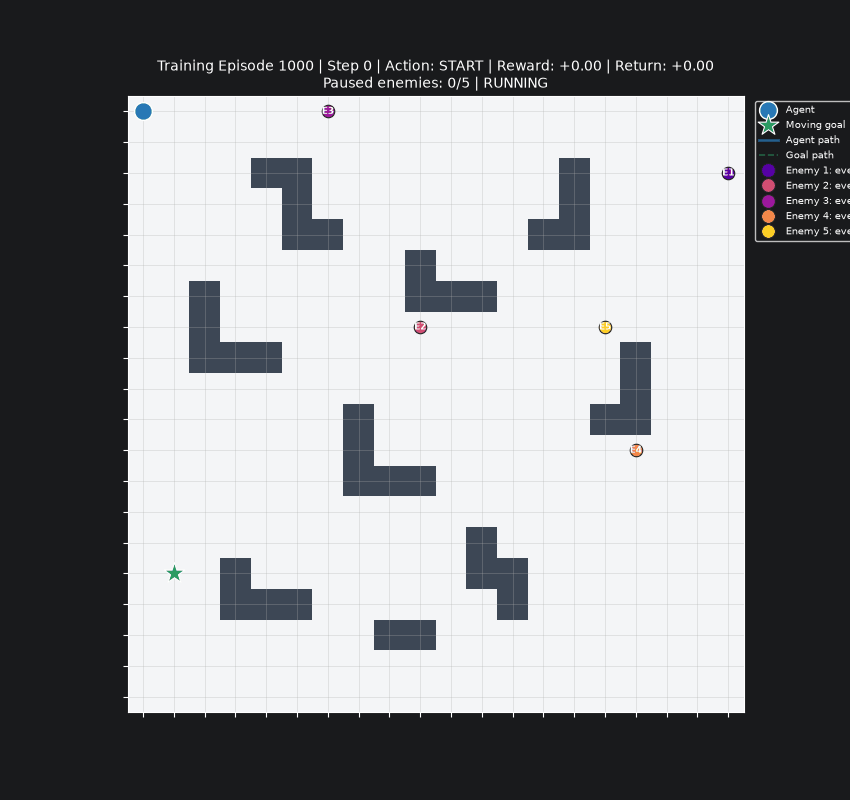

In [8]:
video_results = render_stochastic_enemy_episode_videos(
    episode_dir=OUTPUT_DIR / "episodes",
    episodes=VIDEO_EPISODES,
    output_dir=OUTPUT_DIR / "videos",
    fps=10,
    save_mp4=True,
)

for result in video_results:
    print(
        f"Episode {result['episode']}: success={result['success']}, "
        f"steps={result['steps']}"
    )
    display(Image(filename=result["gif_path"]))
    if result["mp4_path"]:
        print("MP4:", result["mp4_path"])

## 7. Greedy evaluation

Evaluation disables epsilon exploration, does not update the network, and uses fresh environment seeds. In addition to navigation metrics, it reports how many enemy movement and pause events occurred during an average episode.

In [13]:
evaluation = evaluate_stochastic_enemy_policy(
    agent,
    num_episodes=NUM_EVAL_EPISODES,
    seed=TRAIN_CONFIG.evaluation_seed,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
)
evaluation_frame = pd.DataFrame([evaluation])
display(evaluation_frame.T.rename(columns={0: "Value"}))
evaluation_frame.to_csv(
    OUTPUT_DIR / "evaluation_stochastic_enemies.csv",
    index=False,
)

agent.save(
    OUTPUT_DIR / "dqn_stochastic_enemies_final.pt",
    extra={
        "scenario": "moving_goal_stochastic_enemies",
        "episodes": NUM_EPISODES,
        "seed": SEED,
        "max_steps": MAX_STEPS,
        "goal_move_interval": GOAL_MOVE_INTERVAL,
        "enemy_speed_intervals": list(ENEMY_SPEED_INTERVALS),
        "pause_probability": PAUSE_PROBABILITY,
        "pause_duration": list(PAUSE_DURATION),
    },
)
print("Checkpoint saved") # , OUTPUT_DIR / "dqn_stochastic_enemies_final.pt")

,Value
success_rate,1.000000
average_return,29.443125
average_steps,21.315000
blocked_action_rate,0.000000
average_goal_moves,6.345000
average_enemy_moves_per_episode,32.670000
average_enemy_paused_steps_per_episode,19.630000


Checkpoint saved


## 8. Inspect one greedy rollout

The map below is for analysis only. The Agent still selects actions from the 24-dimensional local observation; it is not given the complete enemy map.

Success: True
Steps: 30
Enemy moves: 40
Enemy pause steps: 35


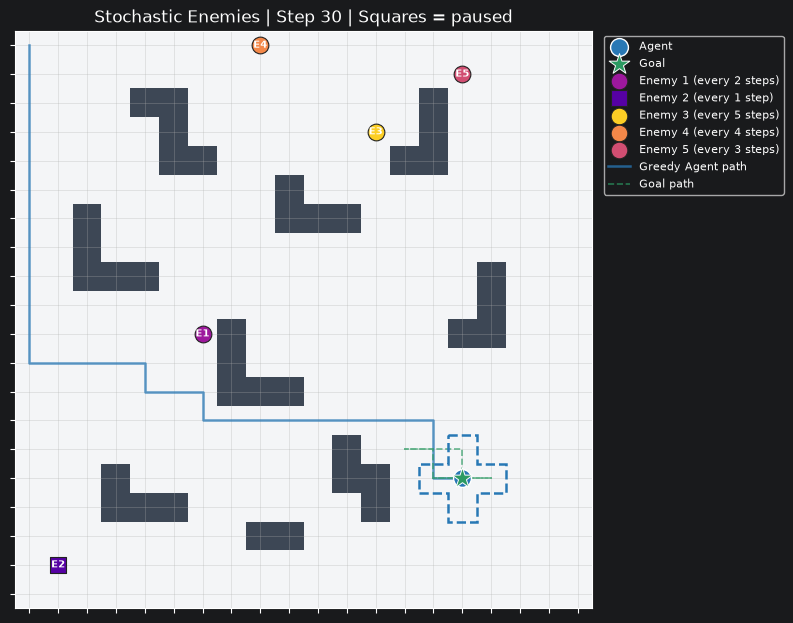

In [10]:
rollout_env = StochasticEnemyNavigationGridWorld(
    gamma=agent.config.gamma,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
)
obs, reset_info = rollout_env.reset(seed=60_001)
agent_path = [rollout_env.agent_pos]
goal_path = [rollout_env.goal_pos]
rollout_enemy_moves = 0
rollout_enemy_pauses = 0
terminated = truncated = False
last_info = reset_info

while not (terminated or truncated):
    action = agent.choose_action(obs, explore=False)
    obs, reward, terminated, truncated, last_info = rollout_env.step(action)
    agent_path.append(rollout_env.agent_pos)
    goal_path.append(rollout_env.goal_pos)
    rollout_enemy_moves += last_info["enemies_moved_count"]
    rollout_enemy_pauses += last_info["enemies_paused_count"]

print("Success:", last_info["success"])
print("Steps:", last_info["steps"])
print("Enemy moves:", rollout_enemy_moves)
print("Enemy pause steps:", rollout_enemy_pauses)

fig, ax = plt.subplots(figsize=(8, 8))
rollout_env.render(ax=ax, show_sensor=True)
ax.plot(
    [position[1] for position in agent_path],
    [position[0] for position in agent_path],
    color="#2878b5", linewidth=1.8, alpha=0.75, label="Greedy Agent path",
)
ax.plot(
    [position[1] for position in goal_path],
    [position[0] for position in goal_path],
    color="#2b9a62", linewidth=1.2, linestyle="--", alpha=0.7,
    label="Goal path",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
plt.tight_layout()
plt.show()

## Interpretation and research notes

- A non-zero pause probability makes enemy motion stochastic even when an enemy has reached its movement interval.
- The speed interval controls the frequency of movement opportunities, not a guaranteed displacement. A blocked enemy or a paused enemy can remain in place.
- The Agent has only local obstacle sensing and no recurrent memory. Therefore the task remains partially observable; a feed-forward DQN may not infer an enemy's speed from one observation.
- Compare success rate and blocked-action rate against version 03 using multiple independent training seeds. Do not draw a research conclusion from one seed.
- A natural next experiment is to keep this environment fixed and compare vanilla DQN with Double DQN or a recurrent DQN (DRQN), isolating the effect of the learning algorithm from the environment change.

In [15]:
# Independent Evaluation — Unseen Random Seeds

CHECKPOINT_PATH = OUTPUT_DIR / "dqn_stochastic_enemies_final.pt"

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Trained checkpoint not found: {CHECKPOINT_PATH}"
    )

# Load the trained model. No training will happen.
test_agent = DQNAgent.load(CHECKPOINT_PATH, map_location=DEVICE)

# Completely new evaluation episodes
TEST_EPISODES = 1000
TEST_SEED = 100_000

print("Loading trained model") #:, CHECKPOINT_PATH)
print("Evaluation episodes:", TEST_EPISODES)
print("Evaluation seed:", TEST_SEED)
print("Exploration: DISABLED")
print("Learning: DISABLED")

# Run evaluation on fresh stochastic episodes
test_results = evaluate_stochastic_enemy_policy(
    agent=test_agent,
    num_episodes=TEST_EPISODES,
    seed=TEST_SEED,
    max_steps=MAX_STEPS,
    goal_move_interval=GOAL_MOVE_INTERVAL,
    enemy_speed_intervals=ENEMY_SPEED_INTERVALS,
    pause_probability=PAUSE_PROBABILITY,
    pause_duration=PAUSE_DURATION,
)

# Display results
test_df = pd.DataFrame([test_results])
display(test_df.T.rename(columns={0: "Value"}))

print(
    f"\nIndependent Success Rate: "
    f"{test_results['success_rate'] * 100:.2f}%"
)

# Save independent evaluation results
test_df.to_csv(
    OUTPUT_DIR / "independent_evaluation_1000.csv",
    index=False,
)

print("\nResults saved successfully.")


Loading trained model
Evaluation episodes: 1000
Evaluation seed: 100000
Exploration: DISABLED
Learning: DISABLED


,Value
success_rate,1.000000
average_return,29.793575
average_steps,22.015000
blocked_action_rate,0.000000
average_goal_moves,6.616000
average_enemy_moves_per_episode,33.673000
average_enemy_paused_steps_per_episode,20.351000



Independent Success Rate: 100.00%

Results saved successfully.
